# Task 2: Customer Segmentation Analysis

## Project Overview
The objective of this project is to segment customers based on their purchasing behaviour using the K-Means Clustering algorithm. It aims to identify different customer groups, understand their spending patterns, and provide insights to support targeted marketing strategies and improve customer retention.

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [62]:
# Load datasets
customers = pd.read_csv("data/olist_customers_dataset.csv")
orders = pd.read_csv("data/olist_orders_dataset.csv")
payments = pd.read_csv("data/olist_order_payments_dataset.csv")

In [63]:
print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Payments:", payments.shape)

Customers: (99441, 5)
Orders: (99441, 8)
Payments: (103886, 5)


## Data Inspection

In [64]:
print("Customers Dataset:")
display(customers.head())

print("Orders Dataset:")
display(orders.head())

print("Payments Dataset:")
display(payments.head())

# Check dataset information
print("\nCustomers Info:")
customers.info()

print("\nOrders Info:")
orders.info()

print("\nPayments Info:")
payments.info()

Customers Dataset:


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


Orders Dataset:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


Payments Dataset:


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45



Customers Info:
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB

Orders Info:
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order

## Data Cleaning and Preparation

In [65]:
# Check missing values
print("Missing Values:")
print("Customers:", customers.isnull().sum().sum())
print("Orders:", orders.isnull().sum().sum())
print("Payments:", payments.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate Records:")
print("Customers:", customers.duplicated().sum())
print("Orders:", orders.duplicated().sum())
print("Payments:", payments.duplicated().sum())

Missing Values:
Customers: 0
Orders: 4908
Payments: 0

Duplicate Records:
Customers: 0
Orders: 0
Payments: 0


In [66]:
# Remove records with missing essential values
customers = customers.dropna(subset=['customer_id','customer_unique_id'])
orders = orders.dropna(subset=['order_id','customer_id','order_purchase_timestamp'])

In [67]:
# Check missing values column-wise
print("Missing Values in Orders Dataset:")
print(orders.isnull().sum()[orders.isnull().sum() > 0])

Missing Values in Orders Dataset:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64


In [68]:
# Convert order purchase date into datetime format
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'],errors='coerce'
)
print(orders['order_purchase_timestamp'].dtype)

datetime64[us]


In [69]:
customers = customers[['customer_id', 'customer_unique_id']]

orders = orders[['order_id','customer_id','order_status','order_purchase_timestamp']]

payments = payments[['order_id', 'payment_value']]

# Aggregate payments by order
payments = payments.groupby(
    'order_id', as_index=False
)['payment_value'].sum()

print("Data preparation completed.")
print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Payments:", payments.shape)

Data preparation completed.
Customers: (99441, 2)
Orders: (99441, 4)
Payments: (99440, 2)


## Data Integration

In [70]:
# Merge customers with orders
merged_data = pd.merge(orders,customers,on='customer_id',how='inner')

# Merge with payment data
merged_data = pd.merge(merged_data,payments,on='order_id',how='inner')

print("Merged Dataset Shape:", merged_data.shape)
display(merged_data.head())

Merged Dataset Shape: (99440, 6)


,order_id,customer_id,order_status,order_purchase_timestamp,customer_unique_id,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,7c396fd4830fd04220f754e42b4e5bff,38.71
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,af07308b275d755c9edb36a90c618231,141.46
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,3a653a41f6f9fc3d2a113cf8398680e8,179.12
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,7c142cf63193a1473d2e66489a9ae977,72.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,72632f0f9dd73dfee390c9b22eb56dd6,28.62


## Customer Behaviour Metrics

In [71]:
reference_date = merged_data['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

customer_metrics = merged_data.groupby('customer_unique_id').agg(Recency=('order_purchase_timestamp', lambda x: (reference_date - x.max()).days),
    Frequency=('order_id', 'nunique'),
    Monetary=('payment_value', 'sum')).reset_index()

customer_metrics['Total_Purchases'] = customer_metrics['Frequency']
customer_metrics['Average_Purchase_Value'] = customer_metrics['Monetary'] / customer_metrics['Frequency']
customer_metrics['CLV'] = customer_metrics['Monetary']

display(customer_metrics.head())

print("Total Customers:", len(customer_metrics))
print("Average Purchase Value:", customer_metrics['Average_Purchase_Value'].mean())
print("Average Purchase Frequency:", customer_metrics['Frequency'].mean())
print("Average Customer Lifetime Value:", customer_metrics['CLV'].mean())

,customer_unique_id,Recency,Frequency,Monetary,Total_Purchases,Average_Purchase_Value,CLV
0,0000366f3b9a7992bf8c76cfdf3221e2,161,1,141.90,1,141.90,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,164,1,27.19,1,27.19,27.19
2,0000f46a3911fa3c0805444483337064,586,1,86.22,1,86.22,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,370,1,43.62,1,43.62,43.62
4,0004aac84e0df4da2b147fca70cf8255,337,1,196.89,1,196.89,196.89


Total Customers: 96095
Average Purchase Value: 161.40179554585072
Average Purchase Frequency: 1.0348093032936156
Average Customer Lifetime Value: 166.59422571413705


## Feature Selection for Clustering

In [72]:
rfm = customer_metrics[['Recency', 'Frequency', 'Monetary']].copy()
display(rfm.head())

print("RFM Dataset Shape:", rfm.shape)

,Recency,Frequency,Monetary
0,161,1,141.90
1,164,1,27.19
2,586,1,86.22
3,370,1,43.62
4,337,1,196.89


RFM Dataset Shape: (96095, 3)


## Feature Standardization

In [73]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

# Convert scaled data into DataFrame
rfm_scaled = pd.DataFrame(rfm_scaled,columns=['Recency', 'Frequency', 'Monetary'])

display(rfm_scaled.head())

,Recency,Frequency,Monetary
0,-0.832626,-0.162369,-0.106704
1,-0.813071,-0.162369,-0.602366
2,1.937781,-0.162369,-0.347297
3,0.529762,-0.162369,-0.531372
4,0.314648,-0.162369,0.130908


## Elbow Method

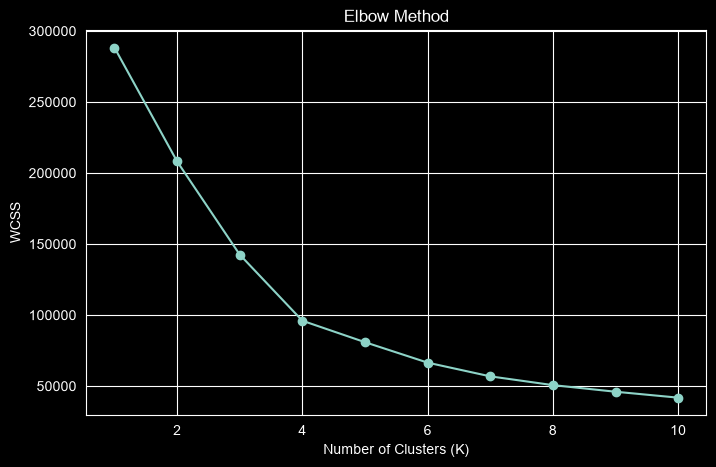

In [74]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

# Plot Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

## Applying K-Means Clustering

In [75]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

customer_metrics['Cluster'] = kmeans.fit_predict(rfm_scaled)
display(customer_metrics.head())

print(customer_metrics['Cluster'].value_counts().sort_index())

,customer_unique_id,Recency,Frequency,Monetary,Total_Purchases,Average_Purchase_Value,CLV,Cluster
0,0000366f3b9a7992bf8c76cfdf3221e2,161,1,141.90,1,141.90,141.90,2
1,0000b849f77a49e4a4ce2b2a4ca5be3f,164,1,27.19,1,27.19,27.19,2
2,0000f46a3911fa3c0805444483337064,586,1,86.22,1,86.22,86.22,1
3,0000f6ccb0745a6a4b88665a16c9f078,370,1,43.62,1,43.62,43.62,1
4,0004aac84e0df4da2b147fca70cf8255,337,1,196.89,1,196.89,196.89,1


Cluster
0     3005
1    39643
2    53447
Name: count, dtype: int64


## Visualizing Customer Clusters

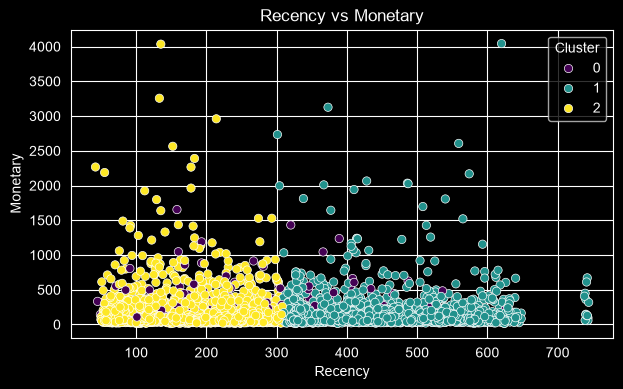

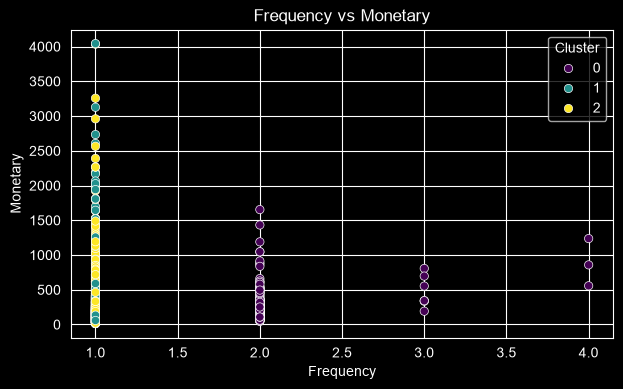

In [76]:
plot_data = customer_metrics.sample(min(5000, len(customer_metrics)), random_state=42)

for x in ['Recency', 'Frequency']:
    plt.figure(figsize=(7, 4))
    sns.scatterplot(data=plot_data, x=x, y='Monetary', hue='Cluster', palette='viridis')
    plt.title(f'{x} vs Monetary')
    plt.show()

## Cluster Profiling

In [77]:
cluster_profile = customer_metrics.groupby('Cluster').agg(Customers=('customer_unique_id', 'count'),Recency=('Recency', 'mean'),Frequency=('Frequency', 'mean'),Monetary=('Monetary', 'mean')).round(2)

display(cluster_profile)

,Customers,Recency,Frequency,Monetary
Cluster,,,,
0,3005,269.23,2.11,333.15
1,39643,438.89,1.00,162.86
2,53447,178.45,1.00,160.00


## Cluster Insights

- **Cluster 0:** High-value repeat customers.
- **Cluster 1:** Moderate-spending customers with the highest recency.
- **Cluster 2:** Largest group with lower average spending and lowest recency.

## Customer Distribution Across Clusters

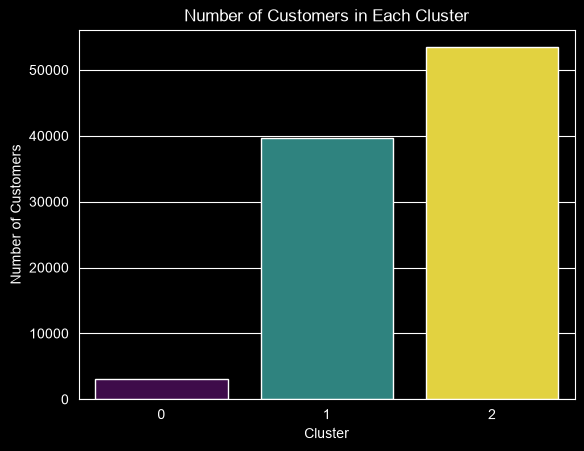

In [78]:
sns.countplot(data=customer_metrics, x='Cluster', hue='Cluster', palette='viridis', legend=False)
plt.title('Number of Customers in Each Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.show()

## 12. Marketing Recommendations

- **Cluster 0:** Offer loyalty rewards and premium deals to encourage repeat purchases.
- **Cluster 1:** Use personalized offers and product recommendations to increase customer engagement.
- **Cluster 2:** Provide discounts and promotional campaigns to encourage repeat purchases.

## 13. Conclusion

Customer segmentation was successfully performed using the K-Means clustering algorithm based on RFM features. Three customer segments were identified with different purchasing behaviours. The analysis helps understand customer spending patterns and supports targeted marketing strategies, customer engagement, and retention.